# 14 · Bibliographic coupling on the Stelmakh et al. gold standard

**Question.** Does bibliographic coupling (the rated paper and a researcher's own paper cite the same works) predict human-rated reviewing expertise on its own, and does it add anything on top of a dense embedding score? Phase 5 found that co-citation expansion added nothing significant on top of Qwen3-Embedding; coupling is a different signal, available as soon as a paper is published. "No gain over dense" is a reportable result.

Data card: `audit/GOLDSTANDARD_DATA.md`. Module: `src/bibcoupling.py` (tests in `tests/test_bibcoupling.py`). Reference fetch: `scripts/fetch_goldstandard_openalex.py`.

## Pre-registration (committed before any coupling or fusion score was computed)

There is no dev/test split, so everything below is fixed in advance.

**Data.** Profiles `d_20_1..10`, 58 participants, 477 ratings. Text = title + abstract as given in the dataset files.

**Reference source: OpenAlex**, one id space per run (never mixed with Semantic Scholar ids).
- Coverage, papers with at least one reference: profile papers 696/867 (80.3%) in OpenAlex vs 286/867 (33.0%) in Semantic Scholar; rated papers 401/463 (86.6%) vs 282/463 (60.9%). OpenAlex is used; it is above the 70% stop line for profile papers.
- Mapping: the paper's DOI (from the Semantic Scholar record), else its arXiv id via DOI `10.48550/arxiv.<id>`. Results are matched to requests through every DOI a record carries (OpenAlex returns merged records). 115 papers stay unmapped: 114 have neither id (the planned title search was not run: it did not fit the day's anonymous API budget, and coverage already passes) and 1 has an id OpenAlex did not resolve.
- Reference list of a paper = `referenced_works` of its DOI record, or of its arXiv record if the DOI record's list is empty.
- Identity of a paper for citation tests = every OpenAlex id it maps to (DOI and arXiv records), so a citation of the preprint version counts.
- **Same-record rule.** If a rated paper and a profile paper map to a shared OpenAlex record (e.g. preprint and published version under two Semantic Scholar ids), that profile paper is left out of the rated paper's coupling and citation scores. The number of such pairs is reported. Embeddings use the dataset's profiles unchanged, as the published baselines do.

**Primary method (the headline number): IDF-weighted cosine coupling, max over profile papers.**
- IDF weight of a referenced work: `log((N + 1) / (c + 1))`, floored at 0, where `c` = its OpenAlex `cited_by_count` (fetched 2026-10-15) and `N` = the number of OpenAlex works with at least one reference (one meta count, same day). A referenced work whose count was not returned (4,078 of 29,579, 13.8%; probably merged or deleted ids) gets the median weight of the works that have one, so it still counts as a shared reference.
- Rated papers with no shared reference tie at 0; ties cost half (official metric). No tie-breaking.

**Headline metric.** The official pooled weighted Kendall-tau loss (lower is better), averaged over the 10 profile samples, with a 95% CI from 1,000 participant bootstrap pools (seed 0, the same pools for every method; the official script is unseeded). Computed with the port in `src/bibcoupling.py`, which reproduces every published baseline from the authors' prediction files; the authors' `evaluation_script.py` is not run because it imports code from the downloaded data folder.

**Ablations** (one table, labelled as ablation; never "chosen"): coupling kind {overlap, Jaccard, cosine, IDF-cosine} × aggregation {max, mean, mean of top 3}.

**Direct citation, reported separately:**
- *Forward citation*: number of profile papers the rated paper cites (the app case: an external paper cites a researcher's work).
- *Reverse citation*: number of profile papers that cite the rated paper. A selection artefact (participants rated papers they had read and may have cited); never folded into coupling.

**Baselines** (same profiles, same metric): MiniLM (`all-MiniLM-L6-v2`), SPECTER2 (`allenai/specter2_base`, [CLS] pooling), Qwen3-Embedding-8B (Q4_K_M on llama-server, last-token pooling, no instruction prefix: `src/jan.embed` sends the plain text, as in v2), cosine, max over profile papers. Published baselines are read from the authors' prediction files.
- **Sanity check, not a selection.** SPECTER2 [CLS] max should land near the published 0.221. A gap above 0.02 triggers a check of text construction and pooling before any baseline is trusted.
- **Qwen3 pooling precondition** (done before this run, `docs/DEVLOG.md` 2026-10-15). No reference weights are local, so the server was checked against the earlier verified v2 setup: 5 texts re-embedded now match the cached v2 vectors (cosine 1.0000), and the server log shows `--pooling last` with no override warning.

**Fusion** of the primary coupling score with each embedding (per participant and sample):
- linear: `α · z(coupling) + (1 − α) · z(embedding)`, z-scores within participant, α ∈ {0, 0.1, …, 1};
- RRF: `1/(k + rank_coupling) + 1/(k + rank_embedding)`, ties share their mean rank, k ∈ {1, 2, 5, 10, 20, 60}.
- α and k are chosen by leave-one-participant-out: for each participant, the value with the lowest mean pooled loss on the other 57. Only these held-out predictions are reported.

**Tests.** Per-participant loss = that participant's own loss averaged over the 10 samples (participants whose ratings are all equal are dropped). Two-sided paired Wilcoxon signed-rank (scipy default `zero_method="wilcox"`: participants with a zero difference drop out of that test; the `ties` column counts them), Holm-corrected within each family:
- *Family 1 (10 tests)*: coupling vs constant (loss 0.5); coupling vs MiniLM, SPECTER2, Qwen3; linear fusion vs its embedding alone (×3); RRF fusion vs its embedding alone (×3). If Qwen3 cannot be run, the family shrinks to 7.
- *Family 2 (2 tests, descriptive)*: forward citation vs constant; reverse citation vs constant.

**Coverage stratification.** Max-aggregated scores cannot split a participant's loss cleanly, so it is done on rated-paper pairs: pooled loss over pairs where both rated papers share at least one reference with the profile, vs all other pairs, for coupling and each embedding.

**Examples.** Sample `d_20_1`, discordant pairs where coupling and Qwen3 (or SPECTER2 if Qwen3 is missing) order two rated papers differently and coupling is not tied: the 4 pairs with the largest true score difference, at most one per participant.

**Addendum (2026-10-19, before the sensitivity run).** The title search left out above was run afterwards (two days, anonymous budget). A hit needs year ±1, a shared author surname, and the same title (normalized similarity ≥ 0.9, or the shorter title of ≥ 3 words contained in the longer); 5 hits from the first pass failed the title rule and were dropped. With `TITLE_SEARCH = True` a paper's records also include its title hit, the IDF counts include the new referenced works, and outputs get the suffix `_titlesearch`. This is a **coverage sensitivity analysis**; the pre-registered run above (`TITLE_SEARCH = False`) stays the headline.

**Scope.** The dataset tests the researcher–paper scoring function *within* one researcher (papers ranked for one person), not calibration across researchers, and it is almost all CS/ML.

In [1]:
GOLDSTANDARD_DIR = ""   # absolute path to the gold-standard clone; papermill -p, or env GOLDSTANDARD_DIR
QWEN = True             # run Qwen3-Embedding-8B (llama-server must be up)
TITLE_SEARCH = False    # addendum: also use title-search hits (coverage sensitivity)
N_BOOT = 1000
SEED = 0

In [2]:
# Parameters
GOLDSTANDARD_DIR = "/Users/senaoz/Developer/SWE-599/research/data/external/goldstandard"


In [3]:
import json
import os
import sys
from collections import Counter
from pathlib import Path

RESEARCH = Path.cwd().parent if Path.cwd().name == "v2" else Path.cwd()
sys.path.insert(0, str(RESEARCH))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)

from src import bibcoupling as bc
from src.figures import INK, INK_2, SLOTS, save, setup_style
from src.rankers_v2 import EmbeddingCache
from src.stats_v2 import holm

G = Path(GOLDSTANDARD_DIR or os.environ["GOLDSTANDARD_DIR"])
OA = RESEARCH / "data" / "external" / "openalex_refs"
EMB_CACHE = RESEARCH / "data" / "v2" / "embeddings_goldstandard"
OUT = RESEARCH / "v2" / "goldstandard"
SUFFIX = "_titlesearch" if TITLE_SEARCH else ""
PRED_DIR = OUT / f"predictions{SUFFIX}"
SAMPLES = range(1, 11)
for d in (OUT, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)

## Data

In [4]:
ev = pd.read_csv(G / "data" / "evaluations.csv", sep="\t")
refs = {}
for _, r in ev.iterrows():
    refs[str(r.ParticipantID)] = {r[f"Paper{i}"]: float(r[f"Expertise{i}"]) for i in range(1, 11)
                                  if isinstance(r[f"Paper{i}"], str) and not pd.isna(r[f"Expertise{i}"])}
REVIEWERS = sorted(refs)

subs, profiles = {}, {}   # paper id -> text; sample -> reviewer -> [profile paper ids]
text, titles = {}, {}
for i in SAMPLES:
    D = G / "evaluation_datasets" / f"d_20_{i}"
    for pid, s in json.load(open(D / "submissions.json")).items():
        text.setdefault(pid, f"{s['content']['title']} {s['content'].get('abstract') or ''}".strip())
        titles.setdefault(pid, s["content"]["title"])
    profiles[i] = {}
    for rv in REVIEWERS:
        rows = [json.loads(l) for l in open(D / "archives" / f"~{rv}.jsonl")]
        profiles[i][rv] = [x["id"] for x in rows]
        for x in rows:
            text.setdefault(x["id"], f"{x['content']['title']} {x['content'].get('abstract') or ''}".strip())
missing = [(rv, p) for rv in REVIEWERS for p in refs[rv] if p not in text]
print(f"participants {len(REVIEWERS)}, ratings {sum(map(len, refs.values()))}, papers with text {len(text)}, rated papers without text {len(missing)}")
print("profile sizes (sample 1): median", np.median([len(v) for v in profiles[1].values()]))

participants 58, ratings 477, papers with text 1311, rated papers without text 0
profile sizes (sample 1): median 19.5


In [5]:
oa = {json.loads(l)["id"]: json.loads(l) for l in open(OA / "papers.jsonl")}
refset, idset = {}, {}
for pid, row in oa.items():
    recs = [row[k] for k in ("doi_record", "arxiv_record", *(("title_record",) if TITLE_SEARCH else ())) if row.get(k)]
    idset[pid] = {r["id"] for r in recs}
    refset[pid] = next((set(r["referenced_works"]) for r in recs if r["referenced_works"]), set())

s2 = {json.loads(l)["id"]: json.loads(l) for l in open(RESEARCH / "data" / "external" / "s2_refs" / "refs.jsonl")}
rated_ids = {p for rv in REVIEWERS for p in refs[rv]}
prof_ids = {p for i in SAMPLES for v in profiles[i].values() for p in v}
cov = pd.DataFrame([
    {"papers": name, "n": len(S),
     "mapped to OpenAlex": sum(bool(idset.get(p)) for p in S),
     "OpenAlex ≥1 ref": sum(bool(refset.get(p)) for p in S),
     "S2 ≥1 ref": sum(bool(s2[p]["references"]) for p in S)}
    for name, S in [("rated", rated_ids), ("profile", prof_ids), ("all", rated_ids | prof_ids)]])
for c in ("OpenAlex ≥1 ref", "S2 ≥1 ref"):
    cov[c + " %"] = (100 * cov[c] / cov["n"]).round(1)
assert cov.set_index("papers").loc["profile", "OpenAlex ≥1 ref %"] >= 70, "STOP: profile coverage below 70%"
cov

,papers,n,mapped to OpenAlex,OpenAlex ≥1 ref,S2 ≥1 ref,OpenAlex ≥1 ref %,S2 ≥1 ref %
0,rated,463,450,401,282,86.6,60.9
1,profile,867,765,696,286,80.3,33.0
2,all,1311,1196,1080,554,82.4,42.3


In [6]:
cited = {}
for name in ("cited_by.jsonl", *(("cited_by_titlesearch.jsonl",) if TITLE_SEARCH else ())):
    cited.update({json.loads(l)["id"]: json.loads(l)["cited_by_count"] for l in open(OA / name)})
pop = json.load(open(OA / "population.json"))
used = set().union(*refset.values())
counts = {w: c for w, c in cited.items() if c is not None}
idf = bc.idf_weights(counts, pop["works_with_references"])
median_w = float(np.median(list(idf.values())))
for w in used - set(idf):
    idf[w] = median_w
print(f"IDF population N = {pop['works_with_references']:,} (fetched {pop['fetched']})")
print(f"referenced works in use {len(used):,}, with a cited_by_count {len(used & set(counts)):,}, without (median weight {median_w:.2f}) {len(used - set(counts)):,}")
print("IDF weight quantiles (5/50/95%):", np.round(np.percentile([idf[w] for w in used & set(idf)], [5, 50, 95]), 2))

IDF population N = 101,086,105 (fetched 2026-10-15)
referenced works in use 29,205, with a cited_by_count 25,168, without (median weight 13.68) 4,037
IDF weight quantiles (5/50/95%): [10.59 13.68 16.13]


## Scores

In [7]:
KINDS, AGGS = bc.COUPLING_KINDS, bc.AGGREGATIONS

def cprof(i, rv, p):
    """Profile papers used for rated paper p's citation-based scores (same-record rule)."""
    return [q for q in profiles[i][rv] if not (idset.get(p, set()) & idset.get(q, set()))]

same = [(i, rv, p, q) for i in SAMPLES for rv in REVIEWERS for p in refs[rv] for q in profiles[i][rv]
        if idset.get(p, set()) & idset.get(q, set())]
print(f"(sample, participant, rated, profile) pairs sharing an OpenAlex record: {len(same)}; "
      f"distinct (rated, profile) paper pairs: {len({(p, q) for _, _, p, q in same})}")

def coupling_preds(kind, agg):
    out = []
    for i in SAMPLES:
        out.append({rv: {p: bc.aggregate([bc.coupling(refset.get(p, set()), refset.get(q, set()), kind, idf)
                                          for q in cprof(i, rv, p)], agg)
                         for p in refs[rv]} for rv in REVIEWERS})
    return out

def citation_preds(direction):
    out = []
    for i in SAMPLES:
        d = {}
        for rv in REVIEWERS:
            if direction == "forward":
                d[rv] = {p: float(bc.forward_citation(refset.get(p, set()), [idset.get(q, set()) for q in cprof(i, rv, p)])) for p in refs[rv]}
            else:
                d[rv] = {p: float(bc.reverse_citation([refset.get(q, set()) for q in cprof(i, rv, p)], idset.get(p, set()))) for p in refs[rv]}
        out.append(d)
    return out

preds = {f"coupling_{k}_{a}": coupling_preds(k, a) for k in KINDS for a in AGGS}
PRIMARY = "coupling_idf_cosine_max"
preds["forward_citation"] = citation_preds("forward")
preds["reverse_citation"] = citation_preds("reverse")
preds["constant"] = [{rv: {p: 0.0 for p in refs[rv]} for rv in REVIEWERS} for _ in SAMPLES]
print(len(preds), "score sets")

(sample, participant, rated, profile) pairs sharing an OpenAlex record: 0; distinct (rated, profile) paper pairs: 0


15 score sets


In [8]:
EMBED = ["minilm", "specter2"] + (["qwen"] if QWEN else [])

def embed_preds(method):
    cache = EmbeddingCache(method, EMB_CACHE)
    cache.ensure(sorted(set(text.values())))
    vec = {p: v / np.linalg.norm(v) for p, v in zip(text, cache.get([text[p] for p in text]))}
    out = {a: [] for a in AGGS}
    for i in SAMPLES:
        sims = {rv: {p: [float(vec[p] @ vec[q]) for q in profiles[i][rv]] for p in refs[rv]} for rv in REVIEWERS}
        for a in AGGS:
            out[a].append({rv: {p: bc.aggregate(s, a) for p, s in d.items()} for rv, d in sims.items()})
    return out

for m in EMBED:
    e = embed_preds(m)
    for a in AGGS:
        preds[m if a == "max" else f"{m}_{a}"] = e[a]
print("embeddings:", EMBED)

embeddings: ['minilm', 'specter2', 'qwen']


## Main results

In [9]:
published = {"spector2_max": "SPECTER2 max (published)", "o1mini": "o1-mini (published)",
             "specter_mfr": "SPECTER+MFR (published)", "spector2": "SPECTER2 (published)", "tpms": "TPMS (published)"}
for f, name in published.items():
    preds[name] = [json.load(open(G / "predictions" / f"{f}_d_20_{i}_ta.json")) for i in SAMPLES]

rows = []
for name, P in preds.items():
    point, lo, hi = bc.bootstrap_ci(P, refs, N_BOOT, SEED)
    rows.append({"method": name, "loss": point, "lo": lo, "hi": hi})
results = pd.DataFrame(rows).set_index("method")
MAIN = [PRIMARY, "forward_citation", "reverse_citation", *EMBED, *published.values(), "constant"]
results.loc[MAIN].round(3)

,loss,lo,hi
method,,,
coupling_idf_cosine_max,0.299,0.248,0.348
forward_citation,0.468,0.445,0.488
reverse_citation,0.434,0.403,0.463
minilm,0.242,0.194,0.292
specter2,0.231,0.183,0.282
qwen,0.222,0.177,0.274
SPECTER2 max (published),0.221,0.183,0.262
o1-mini (published),0.245,0.205,0.291
SPECTER+MFR (published),0.238,0.184,0.298


In [10]:
abl = results.loc[[f"coupling_{k}_{a}" for k in KINDS for a in AGGS], "loss"].rename(lambda s: s[len("coupling_"):])
abl = pd.DataFrame({a: [abl[f"{k}_{a}"] for k in KINDS] for a in AGGS}, index=KINDS)
print("ABLATION (not used to choose anything; the primary method is idf_cosine / max, fixed in advance)")
abl.round(3)

ABLATION (not used to choose anything; the primary method is idf_cosine / max, fixed in advance)


,max,mean,top3
overlap,0.324,0.319,0.312
jaccard,0.310,0.314,0.308
cosine,0.309,0.308,0.306
idf_cosine,0.299,0.300,0.292


## Fusion (leave-one-participant-out)

In [11]:
ALPHAS = [round(a, 1) for a in np.arange(0, 1.01, 0.1)]
RRF_K = [1, 2, 5, 10, 20, 60]
choices = {}
for m in EMBED:
    lin, ch = bc.lopo_select(lambda a: [bc.fuse_linear(c, e, a) for c, e in zip(preds[PRIMARY], preds[m])], ALPHAS, refs)
    preds[f"fusion_linear_{m}"] = lin
    choices[f"linear_{m}"] = Counter(ch.values())
    rrf, ch = bc.lopo_select(lambda k: [bc.fuse_rrf(c, e, k) for c, e in zip(preds[PRIMARY], preds[m])], RRF_K, refs)
    preds[f"fusion_rrf_{m}"] = rrf
    choices[f"rrf_{m}"] = Counter(ch.values())
    for name in (f"fusion_linear_{m}", f"fusion_rrf_{m}"):
        point, lo, hi = bc.bootstrap_ci(preds[name], refs, N_BOOT, SEED)
        results.loc[name] = [point, lo, hi]
for k, v in choices.items():
    print(k, "held-out choices:", dict(sorted(v.items())))
results.loc[[x for m in EMBED for x in (m, f"fusion_linear_{m}", f"fusion_rrf_{m}")]].round(3)

linear_minilm held-out choices: {np.float64(0.3): 1, np.float64(0.6): 2, np.float64(0.7): 54, np.float64(0.8): 1}
rrf_minilm held-out choices: {10: 1, 20: 57}
linear_specter2 held-out choices: {np.float64(0.4): 57, np.float64(0.5): 1}
rrf_specter2 held-out choices: {1: 4, 2: 51, 20: 3}
linear_qwen held-out choices: {np.float64(0.3): 57, np.float64(0.5): 1}
rrf_qwen held-out choices: {1: 1, 5: 1, 60: 56}


,loss,lo,hi
method,,,
minilm,0.242,0.194,0.292
fusion_linear_minilm,0.233,0.177,0.287
fusion_rrf_minilm,0.233,0.183,0.285
specter2,0.231,0.183,0.282
fusion_linear_specter2,0.197,0.148,0.247
fusion_rrf_specter2,0.230,0.177,0.287
qwen,0.222,0.177,0.274
fusion_linear_qwen,0.212,0.164,0.264
fusion_rrf_qwen,0.230,0.177,0.282


## Paired tests (per-participant loss, Wilcoxon, Holm)

In [12]:
def per_participant(P):
    per = [bc.per_reviewer_loss(p, refs) for p in P]
    return pd.Series({rv: np.mean([d[rv] for d in per]) for rv in per[0]})

pp = pd.DataFrame({m: per_participant(P) for m, P in preds.items()})
print("participants in tests:", len(pp))

def test_family(pairs):
    out = []
    for a, b in pairs:
        diff = pp[a] - pp[b]
        stat, p = wilcoxon(pp[a], pp[b])
        out.append({"a": a, "b": b, "mean loss a": pp[a].mean(), "mean loss b": pp[b].mean(),
                    "mean diff (a-b)": diff.mean(), "a better": int((diff < 0).sum()), "b better": int((diff > 0).sum()),
                    "ties": int((diff == 0).sum()), "W": stat, "p": p})
    t = pd.DataFrame(out)
    t["p_holm"] = holm(t["p"].tolist())
    return t

fam1 = [(PRIMARY, "constant")] + [(PRIMARY, m) for m in EMBED] \
     + [(f"fusion_linear_{m}", m) for m in EMBED] + [(f"fusion_rrf_{m}", m) for m in EMBED]
fam2 = [("forward_citation", "constant"), ("reverse_citation", "constant")]
t1, t2 = test_family(fam1), test_family(fam2)
t1["family"], t2["family"] = 1, 2
tests = pd.concat([t1, t2], ignore_index=True)
num = [c for c in tests.columns if c.startswith(("mean", "W"))]
show = tests.copy()
show[num] = show[num].round(3)
show[["p", "p_holm"]] = show[["p", "p_holm"]].map(lambda x: f"{x:.2e}")
show

participants in tests: 58


,a,b,mean loss a,mean loss b,mean diff (a-b),a better,b better,ties,W,p,p_holm,family
0,coupling_idf_cosine_max,constant,0.303,0.500,-0.197,46,10,2,178.0,4.25e-07,4.25e-06,1
1,coupling_idf_cosine_max,minilm,0.303,0.281,0.023,23,32,3,678.5,4.43e-01,1.00e+00,1
2,coupling_idf_cosine_max,specter2,0.303,0.267,0.036,24,32,2,632.0,1.76e-01,1.00e+00,1
3,coupling_idf_cosine_max,qwen,0.303,0.256,0.048,21,32,5,537.0,1.14e-01,9.12e-01,1
4,fusion_linear_minilm,minilm,0.253,0.281,-0.028,31,18,9,473.0,1.65e-01,1.00e+00,1
5,fusion_linear_specter2,specter2,0.233,0.267,-0.035,35,9,14,211.0,9.19e-04,8.27e-03,1
6,fusion_linear_qwen,qwen,0.254,0.256,-0.001,25,22,11,482.0,3.86e-01,1.00e+00,1
7,fusion_rrf_minilm,minilm,0.265,0.281,-0.016,32,19,7,542.0,2.57e-01,1.00e+00,1
8,fusion_rrf_specter2,specter2,0.263,0.267,-0.004,30,24,4,647.0,4.11e-01,1.00e+00,1
9,fusion_rrf_qwen,qwen,0.264,0.256,0.009,27,25,6,665.0,8.27e-01,1.00e+00,1


## Coverage-stratified results (rated-paper pairs)

In [13]:
def has_overlap(i, rv, p):
    return any(refset.get(p, set()) & refset.get(q, set()) for q in cprof(i, rv, p))

strat = []
for m in [PRIMARY, "forward_citation", *EMBED]:
    for label, want in (("both papers share ≥1 reference with the profile", True), ("all other pairs", False)):
        ls, ns = [], []
        for i in SAMPLES:
            ov = {(rv, p): has_overlap(i, rv, p) for rv in REVIEWERS for p in refs[rv]}
            keep = lambda rv, a, b: (ov[(rv, a)] and ov[(rv, b)]) == want
            l, n = bc.kt_loss_pairs(preds[m][i - 1], refs, keep)
            ls.append(l); ns.append(n)
        strat.append({"method": m, "pairs": label, "loss": np.mean(ls), "pairs per sample": np.mean(ns)})
strat = pd.DataFrame(strat).pivot(index="method", columns="pairs", values="loss")
share = np.mean([np.mean([has_overlap(i, rv, p) for rv in REVIEWERS for p in refs[rv]]) for i in SAMPLES])
print(f"rated (participant, paper) items with ≥1 shared reference with the profile, mean over samples: {share:.1%}")
strat.round(3)

rated (participant, paper) items with ≥1 shared reference with the profile, mean over samples: 70.2%


pairs,all other pairs,both papers share ≥1 reference with the profile
method,,
coupling_idf_cosine_max,0.362,0.233
forward_citation,0.489,0.446
minilm,0.188,0.298
qwen,0.187,0.259
specter2,0.196,0.266


## Examples where coupling and the embedding disagree

In [14]:
REF_EMB = "qwen" if QWEN else "specter2"
c1, e1 = preds[PRIMARY][0], preds[REF_EMB][0]
cands = []
for rv in REVIEWERS:
    for a in refs[rv]:
        for b in refs[rv]:
            if refs[rv][a] > refs[rv][b] and c1[rv][a] != c1[rv][b] and \
               np.sign(c1[rv][a] - c1[rv][b]) != np.sign(e1[rv][a] - e1[rv][b]):
                cands.append((refs[rv][a] - refs[rv][b], rv, a, b))
cands.sort(key=lambda x: (-x[0], x[1], x[2], x[3]))
picked, seen = [], set()
for d, rv, a, b in cands:
    if rv not in seen:
        picked.append((rv, a, b)); seen.add(rv)
    if len(picked) == 4:
        break
title = lambda p: titles[p][:90]
ex = []
for rv, a, b in picked:
    for p in (a, b):
        best = max(cprof(1, rv, p) or profiles[1][rv], key=lambda q: bc.coupling(refset.get(p, set()), refset.get(q, set()), "idf_cosine", idf))
        ex.append({"participant": rv, "rated paper": title(p), "true": refs[rv][p], "coupling": round(c1[rv][p], 3),
                   REF_EMB: round(e1[rv][p], 3), "shared refs (best profile paper)": len(refset.get(p, set()) & refset.get(best, set())),
                   "refs": len(refset.get(p, set()))})
pd.DataFrame(ex)

,participant,rated paper,true,coupling,qwen,shared refs (best profile paper),refs
0,2453556,Erasure Coding in Windows Azure Storage,5.0,0.000,0.681,0,0
1,2453556,"Piggyback: Adding Multiple Tasks to a Single, Fixed Network by Lea...",1.0,0.020,0.560,3,35
2,3364789,Quantifying Voter Biases in Online Platforms,5.0,0.000,0.650,0,51
3,3364789,Deep Neural Networks for Estimation and Inference: Application to ...,1.0,0.013,0.532,1,36
4,50825200,Paper Matching with Local Fairness Constraints,5.0,0.067,0.855,2,27
5,50825200,Joint Passage Ranking for Diverse Multi-Answer Retrieval,1.0,0.161,0.564,6,27
6,7391530,Multi-Input Attention for Unsupervised OCR Correction,5.0,0.097,0.711,4,38
7,7391530,Visually Grounded Neural Syntax Acquisition,1.0,0.059,0.776,4,76


## Figure and outputs

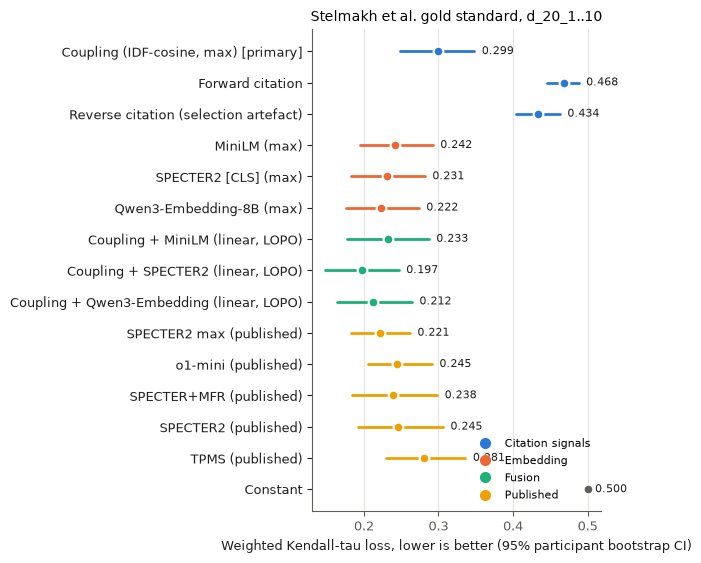

In [15]:
setup_style()
SHORT = {"minilm": "MiniLM", "specter2": "SPECTER2", "qwen": "Qwen3-Embedding"}
order = [PRIMARY, "forward_citation", "reverse_citation", *EMBED, *[f"fusion_linear_{m}" for m in EMBED],
         *published.values(), "constant"]
names = {PRIMARY: "Coupling (IDF-cosine, max) [primary]", "forward_citation": "Forward citation",
         "reverse_citation": "Reverse citation (selection artefact)", "minilm": "MiniLM (max)",
         "specter2": "SPECTER2 [CLS] (max)", "qwen": "Qwen3-Embedding-8B (max)", "constant": "Constant",
         **{f"fusion_linear_{m}": f"Coupling + {SHORT[m]} (linear, LOPO)" for m in EMBED}}
grp = lambda m: 0 if m in (PRIMARY, "forward_citation", "reverse_citation") else 2 if m.startswith("fusion") \
      else 3 if "published" in m else 1
t = results.loc[order[::-1]]
fig, ax = plt.subplots(figsize=(6.4, 0.3 * len(t) + 1.2))
for y, (m, r) in enumerate(t.iterrows()):
    c = SLOTS[grp(m)] if m != "constant" else INK_2
    ax.plot([r.lo, r.hi], [y, y], color=c, lw=2, solid_capstyle="round")
    ax.plot(r.loss, y, "o", color=c, mec="white", mew=1.5)
    ax.text(r.hi + 0.01, y, f"{r.loss:.3f}", va="center", fontsize=8, color=INK)
ax.set_yticks(range(len(t)), [names.get(m, m) for m in t.index])
ax.set_xlabel("Weighted Kendall-tau loss, lower is better (95% participant bootstrap CI)")
ax.set_title("Stelmakh et al. gold standard, d_20_1..10"); ax.grid(axis="y", visible=False)
handles = [plt.Line2D([], [], marker="o", ls="", color=SLOTS[i], label=l)
           for i, l in enumerate(["Citation signals", "Embedding", "Fusion", "Published"])]
ax.legend(handles=handles, loc="lower right", fontsize=8)
fig.tight_layout()
save(fig, f"14_bibcoupling_goldstandard{SUFFIX}")

In [16]:
for name in [PRIMARY, "forward_citation", "reverse_citation", *EMBED, *[f"fusion_{f}_{m}" for f in ("linear", "rrf") for m in EMBED]]:
    algo = name.replace("_", "-")
    for i in SAMPLES:
        with open(PRED_DIR / f"{algo}_d_20_{i}_ta.json", "w") as f:
            json.dump(preds[name][i - 1], f)
results.reset_index().to_csv(OUT / f"14{SUFFIX}_results.csv", index=False, float_format="%.6g")
tests.to_csv(OUT / f"14{SUFFIX}_tests.csv", index=False, float_format="%.6g")
strat.reset_index().to_csv(OUT / f"14{SUFFIX}_stratified.csv", index=False, float_format="%.6g")
cov.to_csv(OUT / f"14{SUFFIX}_coverage.csv", index=False)
print("written:", sorted(p.name for p in OUT.glob(f"14{SUFFIX}_*.csv")), len(list(PRED_DIR.glob("*.json"))), "prediction files")

written: ['14_coverage.csv', '14_results.csv', '14_stratified.csv', '14_tests.csv', '14_titlesearch_coverage.csv', '14_titlesearch_results.csv', '14_titlesearch_stratified.csv', '14_titlesearch_tests.csv'] 185 prediction files
